
# **Project: Fuel Efficiency Prediction and Analysis for Automotive Insights**

# Objective:
## Predict vehicle fuel efficiency (MPG) using automotive attributes and identify the major factors that influence fuel consumption.

## **Author: Rahit Saha**

## Import Libraries

In [1]:
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

# Metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Explainability
import shap


## Load Dataset

In [2]:
df = pd.read_csv("autos_mpg.csv")

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [3]:
df.shape


(398, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


## Dataset Overview

In [5]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])


Rows : 398
Columns : 9


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.514573,7.815984,9.0,17.500,23.0,29.000,46.6
cylinders,398.0,5.454774,1.701004,3.0,4.000,4.0,8.000,8.0
displacement,398.0,193.425879,104.269838,68.0,104.250,148.5,262.000,455.0
weight,398.0,2970.424623,846.841774,1613.0,2223.750,2803.5,3608.000,5140.0
acceleration,398.0,15.568090,2.757689,8.0,13.825,15.5,17.175,24.8
model_year,398.0,76.010050,3.697627,70.0,73.000,76.0,79.000,82.0
origin,398.0,1.572864,0.802055,1.0,1.000,1.0,2.000,3.0


## Check Missing Values

In [7]:
df.isnull().sum()

,0
mpg,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model_year,0
origin,0
car_name,0


## Data Cleaning


### Replace "?" in horsepower

In [8]:
df['horsepower'] = df['horsepower'].replace('?', np.nan)

df['horsepower'] = pd.to_numeric(df['horsepower'])

### Check Missing Values Again

In [9]:
df.isnull().sum()


,0
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
car_name,0


### Fill Missing Values

In [10]:
df['horsepower'].fillna(df['horsepower'].median(),
                        inplace=True)

In [11]:
df.isnull().sum()


,0
mpg,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model_year,0
origin,0
car_name,0


## Duplicate Check

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.drop_duplicates(inplace=True)

# Exploratory Data Analysis

## MPG Distribution

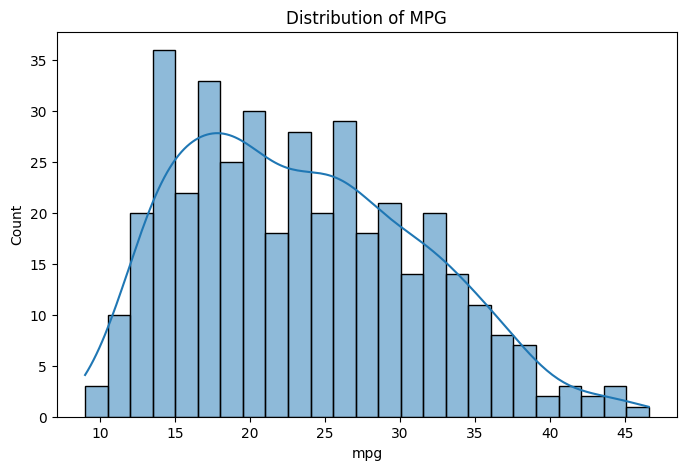

In [14]:
plt.figure(figsize=(8,5))

sns.histplot(df['mpg'],
             bins=25,
             kde=True)

plt.title("Distribution of MPG")
plt.show()

## Horsepower Distribution

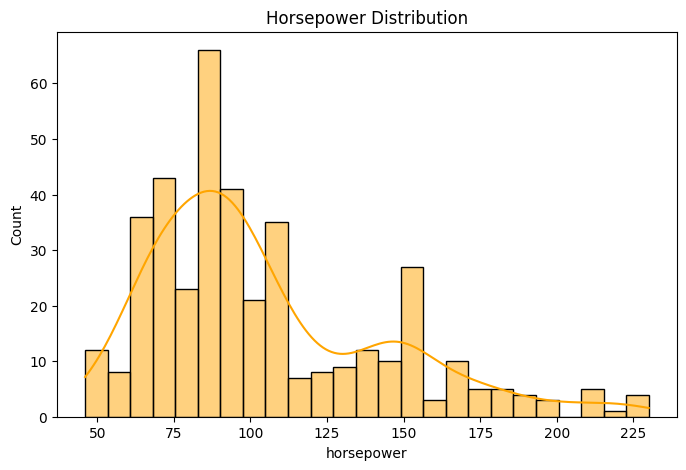

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(df['horsepower'],
             bins=25,
             color='orange',
             kde=True)

plt.title("Horsepower Distribution")
plt.show()

## Weight Distribution

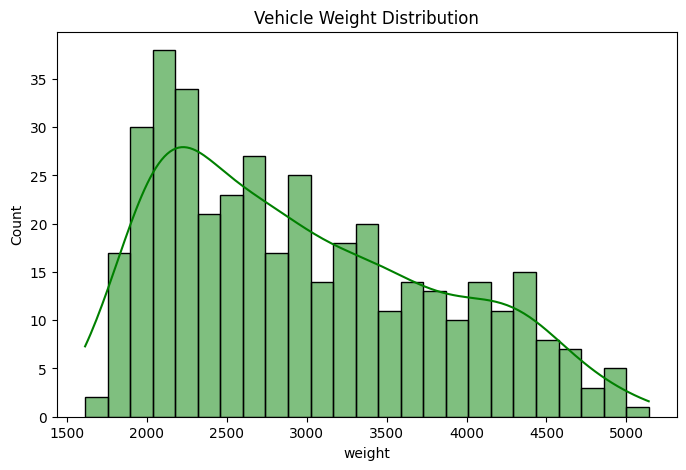

In [16]:
plt.figure(figsize=(8,5))

sns.histplot(df['weight'],
             bins=25,
             color='green',
             kde=True)

plt.title("Vehicle Weight Distribution")
plt.show()

## Univariate Boxplots

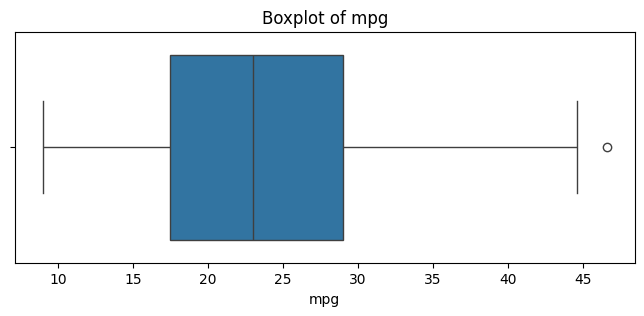

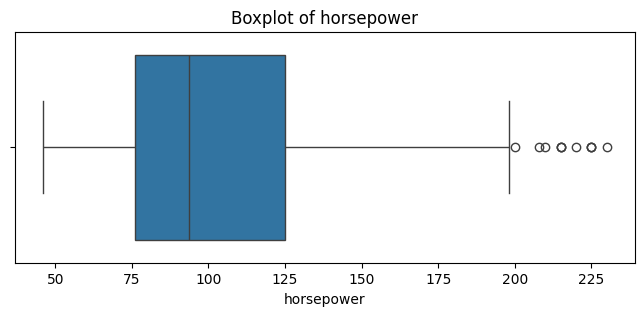

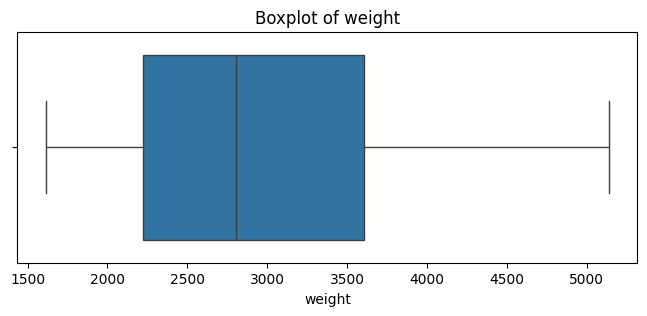

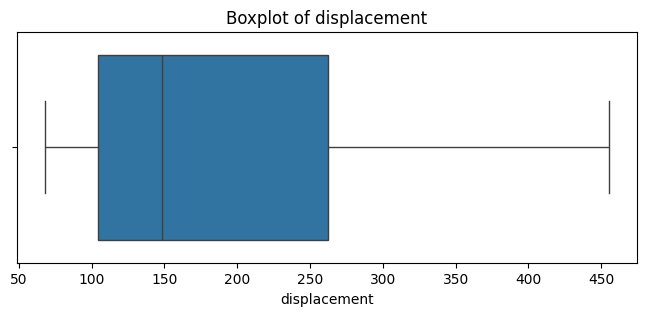

In [17]:
cols = ['mpg',
        'horsepower',
        'weight',
        'displacement']

for col in cols:

    plt.figure(figsize=(8,3))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")

    plt.show()

## Relationship Analysis

### MPG vs Weight

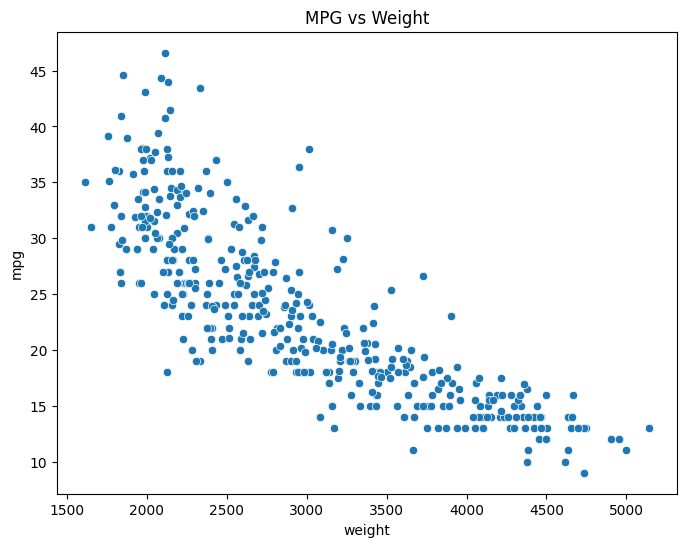

In [18]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    x='weight',
    y='mpg',
    data=df
)

plt.title("MPG vs Weight")
plt.show()

### MPG vs Horsepower

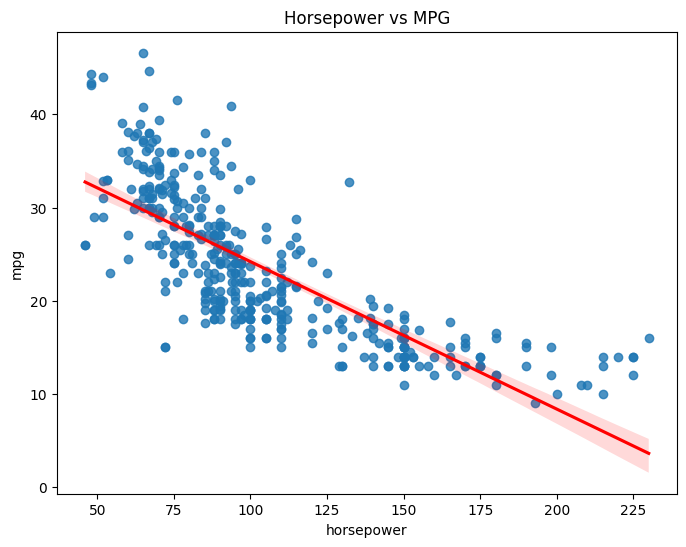

In [19]:
plt.figure(figsize=(8,6))

sns.regplot(
    x='horsepower',
    y='mpg',
    data=df,
    line_kws={'color':'red'}
)

plt.title("Horsepower vs MPG")
plt.show()

### Cylinders vs MPG

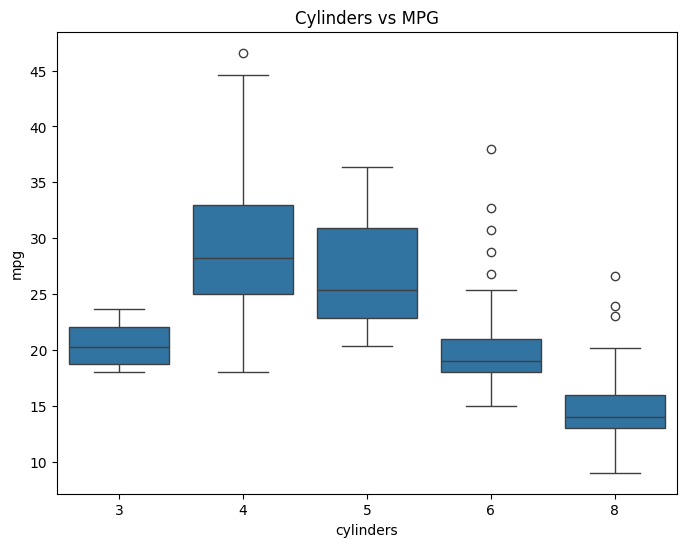

In [20]:
plt.figure(figsize=(8,6))

sns.boxplot(x='cylinders',
            y='mpg',
            data=df)

plt.title("Cylinders vs MPG")
plt.show()

### Model Year vs MPG

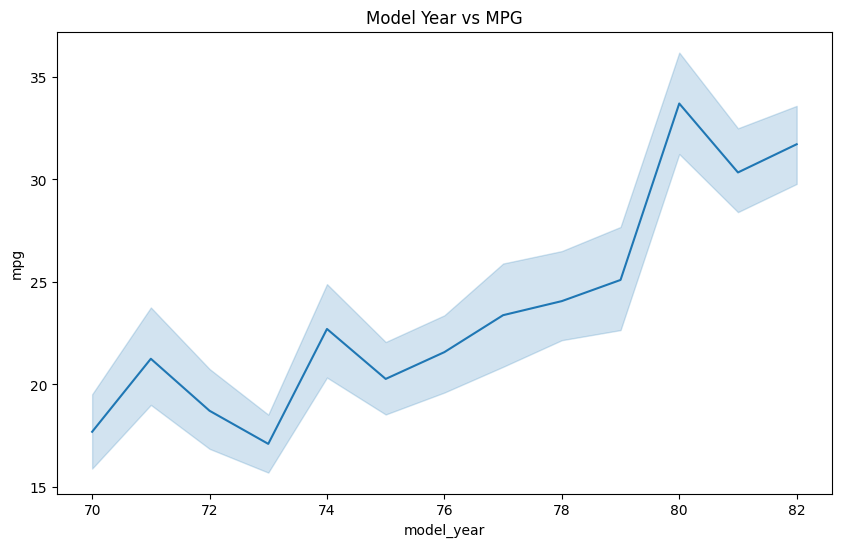

In [21]:
plt.figure(figsize=(10,6))

sns.lineplot(
    x='model_year',
    y='mpg',
    data=df
)

plt.title("Model Year vs MPG")
plt.show()

## Origin Analysis

In [22]:
origin_map = {
    1 : 'USA',
    2 : 'Europe',
    3 : 'Japan'
}

df['origin'] = df['origin'].map(origin_map)

### Average MPG by Origin

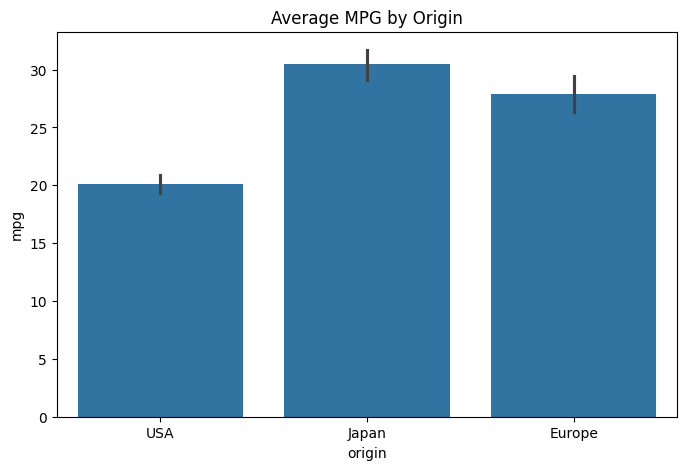

In [23]:
plt.figure(figsize=(8,5))

sns.barplot(
    x='origin',
    y='mpg',
    data=df
)

plt.title("Average MPG by Origin")
plt.show()

# Correlation Analysis

## Drop Car Name Temporarily

In [24]:
temp_df = df.copy()

temp_df['origin'] = temp_df['origin'].map({
    'USA':1,
    'Europe':2,
    'Japan':3
})


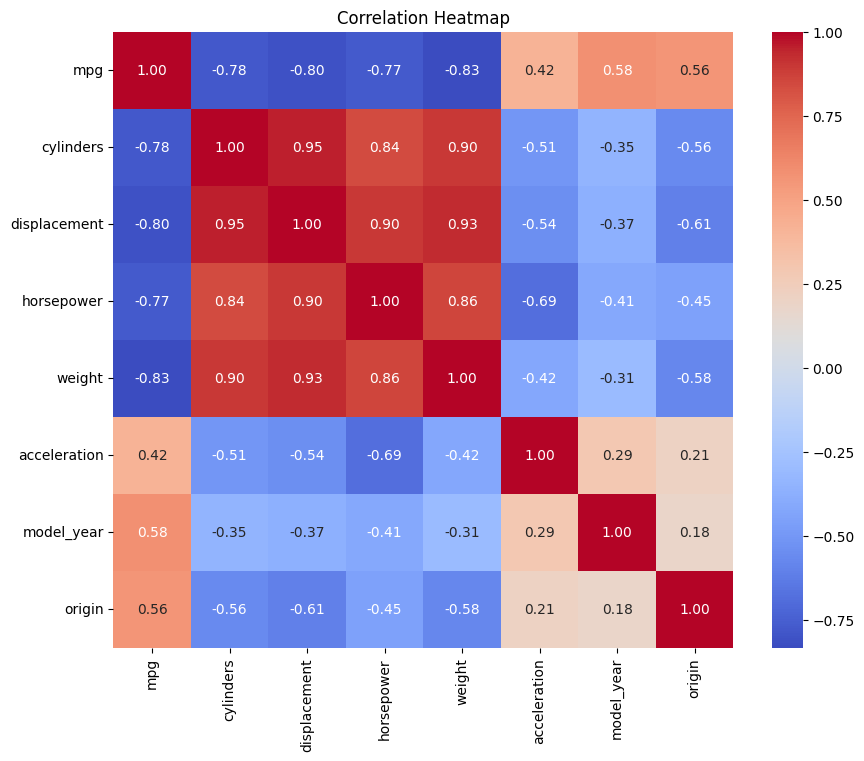

In [25]:
corr = temp_df.corr(numeric_only=True)

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

## Key Findings from the Correlation Heatmap





- Weight has the strongest negative correlation with MPG (-0.83), making it the most influential predictor of fuel efficiency.

- Displacement (-0.80), Cylinders (-0.78), and Horsepower (-0.77) are also strongly negatively correlated with MPG, indicating larger and more powerful engines reduce fuel efficiency.

- Model Year (+0.58) shows a moderate positive correlation with MPG, suggesting newer cars are generally more fuel-efficient.

- Origin (+0.56) has a positive relationship with MPG, indicating fuel efficiency varies across manufacturing regions.

- **Strong multicollinearity exists among engine-related features:**

- Cylinders ↔ Displacement = 0.95
- Displacement ↔ Weight = 0.93
- Cylinders ↔ Weight = 0.90
- Displacement ↔ Horsepower = 0.90

- **Engine size and vehicle size variables carry similar information,** which may cause multicollinearity issues in Linear Regression models.

- **Acceleration has a weak-to-moderate positive correlation with MPG (+0.42)** and a strong negative correlation with Horsepower (-0.69).

**The dataset naturally forms two feature groups:**

- Vehicle/Engine Size: Cylinders, Displacement, Horsepower, Weight
Vehicle Modernity: Model Year, Origin

- For predictive modeling, **Weight, Horsepower, Displacement, and Model Year** appear to be the most informative features.

- Before building a linear model, **VIF analysis or regularization techniques (Ridge/Lasso)** are recommended to handle multicollinearity.

### One-line Conclusion

**Fuel efficiency (MPG) is primarily influenced by vehicle size and engine characteristics, while newer model years contribute positively to improved fuel economy.**



# Feature Engineering

### Drop Car Name

In [26]:
df_model = df.drop('car_name',
                   axis=1)

### One Hot Encoding

In [27]:
df_model = pd.get_dummies(
    df_model,
    columns=['origin'],
    drop_first=True
)

In [28]:
df_model.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_Japan,origin_USA
0,18.0,8,307.0,130.0,3504,12.0,70,False,True
1,15.0,8,350.0,165.0,3693,11.5,70,False,True
2,18.0,8,318.0,150.0,3436,11.0,70,False,True
3,16.0,8,304.0,150.0,3433,12.0,70,False,True
4,17.0,8,302.0,140.0,3449,10.5,70,False,True


## Feature & Target Split

In [29]:
X = df_model.drop('mpg',
                  axis=1)

y = df_model['mpg']

## Train Test Split

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

## Feature Scaling

In [31]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

# Linear Regression Model

In [32]:
lr = LinearRegression()

lr.fit(X_train_scaled,
       y_train)

LinearRegression()

## Prediction

In [33]:
y_pred_lr = lr.predict(X_test_scaled)

## Evaluation

In [34]:
mae_lr = mean_absolute_error(y_test,
                             y_pred_lr)

rmse_lr = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_lr
    )
)

r2_lr = r2_score(
    y_test,
    y_pred_lr
)

print("Linear Regression")

print("MAE :", round(mae_lr,2))
print("RMSE:", round(rmse_lr,2))
print("R2 :", round(r2_lr,2))

Linear Regression
MAE : 2.29
RMSE: 2.89
R2 : 0.84


# Random Forest Model

In [35]:
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    random_state=42
)

rf.fit(X_train,
       y_train)


RandomForestRegressor(max_depth=12, n_estimators=300, random_state=42)

### Prediction

In [36]:
y_pred_rf = rf.predict(X_test)

### Evaluation

In [37]:
mae_rf = mean_absolute_error(
    y_test,
    y_pred_rf
)

rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_rf
    )
)

r2_rf = r2_score(
    y_test,
    y_pred_rf
)

print("Random Forest")

print("MAE :", round(mae_rf,2))
print("RMSE:", round(rmse_rf,2))
print("R2 :", round(r2_rf,2))

Random Forest
MAE : 1.57
RMSE: 2.16
R2 : 0.91


# XGBoost Model

In [38]:
xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

xgb.fit(X_train,
        y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=None, num_parallel_tree=None, ...)

## Prediction

In [39]:
y_pred_xgb = xgb.predict(X_test)

## Evaluation

In [40]:
mae_xgb = mean_absolute_error(
    y_test,
    y_pred_xgb
)

rmse_xgb = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb
    )
)

r2_xgb = r2_score(
    y_test,
    y_pred_xgb
)

print("XGBoost")

print("MAE :", round(mae_xgb,2))
print("RMSE:", round(rmse_xgb,2))
print("R2 :", round(r2_xgb,2))

XGBoost
MAE : 1.84
RMSE: 2.73
R2 : 0.86


# Model Comparison

In [41]:
results = pd.DataFrame({

'Model' : [
    'Linear Regression',
    'Random Forest',
    'XGBoost'
],

'MAE' : [
    mae_lr,
    mae_rf,
    mae_xgb
],

'RMSE' : [
    rmse_lr,
    rmse_rf,
    rmse_xgb
],

'R2' : [
    r2_lr,
    r2_rf,
    r2_xgb
]

})

results.sort_values(
    by='R2',
    ascending=False
)

,Model,MAE,RMSE,R2
1,Random Forest,1.568911,2.156619,0.913496
2,XGBoost,1.844837,2.729651,0.861419
0,Linear Regression,2.288159,2.887673,0.844910


# Random Forest Feature Importance

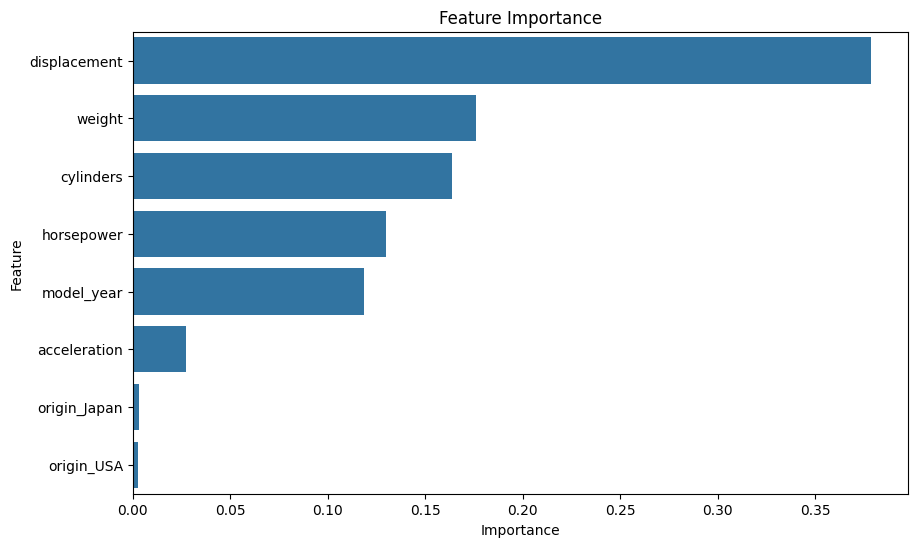

In [42]:
feature_importance = pd.DataFrame({

'Feature' : X.columns,

'Importance':
rf.feature_importances_

})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)


plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance
)

plt.title("Feature Importance")
plt.show()

# Cross Validation Setup

In [43]:
from sklearn.model_selection import (
    KFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)


# K-Fold Cross Validation

Use 5-Fold CV.

In [44]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## Linear Regression CV

In [45]:
lr_cv = cross_val_score(
    LinearRegression(),
    X_train_scaled,
    y_train,
    cv=kfold,
    scoring='r2'
)

print("Linear Regression CV R² Scores:")
print(lr_cv)

print("\nAverage R²:",
      round(lr_cv.mean(),4))

Linear Regression CV R² Scores:
[0.813718   0.77048881 0.80691091 0.79784971 0.82662934]

Average R²: 0.8031


## Random Forest CV

In [46]:
rf_cv = cross_val_score(
    RandomForestRegressor(
        random_state=42
    ),
    X_train,
    y_train,
    cv=kfold,
    scoring='r2'
)

print("Random Forest CV R² Scores:")
print(rf_cv)

print("\nAverage R²:",
      round(rf_cv.mean(),4))

Random Forest CV R² Scores:
[0.87150623 0.87609083 0.8184723  0.81403686 0.88320535]

Average R²: 0.8527


## XGBoost CV

In [47]:
xgb_cv = cross_val_score(
    XGBRegressor(
        random_state=42
    ),
    X_train,
    y_train,
    cv=kfold,
    scoring='r2'
)

print("XGBoost CV Scores:")
print(xgb_cv)

print("\nAverage R²:",
      round(xgb_cv.mean(),4))

XGBoost CV Scores:
[0.85775337 0.86112272 0.79507369 0.8264289  0.85472115]

Average R²: 0.839


# Compare Cross Validation Results

In [48]:
cv_results = pd.DataFrame({

    "Model":[
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],

    "CV_R2":[
        lr_cv.mean(),
        rf_cv.mean(),
        xgb_cv.mean()
    ]

})

cv_results.sort_values(
    by='CV_R2',
    ascending=False
)


,Model,CV_R2
1,Random Forest,0.852662
2,XGBoost,0.839020
0,Linear Regression,0.803119


# Random Forest Hyperparameter Tuning

## Instead of manually choosing parameters, tune them.

In [49]:
rf_params = {

    'n_estimators':[100,200,300,500],

    'max_depth':[5,10,15,None],

    'min_samples_split':[2,5,10],

    'min_samples_leaf':[1,2,4],

    'max_features':['sqrt','log2']

}

## Randomized Search

In [50]:
,rf_random = RandomizedSearchCV(

    estimator=RandomForestRegressor(
        random_state=42
    ),

    param_distributions=rf_params,

    n_iter=30,

    cv=5,

    scoring='r2',

    n_jobs=-1,

    verbose=2,

    random_state=42

)

rf_random.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


RandomizedSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'max_depth': [5, 10, 15, None],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [100, 200, 300, 500]},
                   random_state=42, scoring='r2', verbose=2)

## Best Parameters

In [51]:
rf_random.best_params_

{'n_estimators': 200,
 'min_samples_split': 2,
 'min_samples_leaf': 1,
 'max_features': 'log2',
 'max_depth': 15}

## Best RF Model

In [52]:
best_rf = rf_random.best_estimator_

## RF Predictions

In [53]:
rf_pred = best_rf.predict(
    X_test
)

# RF Evaluation

In [54]:
rf_mae = mean_absolute_error(
    y_test,
    rf_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_pred
    )
)

rf_r2 = r2_score(
    y_test,
    rf_pred
)

print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R² :", rf_r2)


MAE : 1.5882677804487169
RMSE: 2.1459514397534547
R² : 0.9143497828647087


# XGBoost Hyperparameter Tuning

In [55]:
xgb_params = {

    'n_estimators':[100,200,300,400],

    'max_depth':[3,4,5,6,7],

    'learning_rate':[0.01,0.05,0.1],

    'subsample':[0.8,0.9,1],

    'colsample_bytree':[0.8,0.9,1]

}

# Randomized Search CV

In [56]:
xgb_search = RandomizedSearchCV(

    estimator=XGBRegressor(
        random_state=42
    ),

    param_distributions=xgb_params,

    n_iter=30,

    cv=5,

    scoring='r2',

    random_state=42,

    verbose=2,

    n_jobs=-1

)

xgb_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


RandomizedSearchCV(cv=5,
                   estimator=XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=None, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=True,
                                          eval_metric=None, feature_types=None,
                                          feature_weights=None, gamma=None,
                                          grow_policy=None,
                                          importance_type=None,
                                          interaction_constraints...
                                          min_child_weight=None, missing=nan,
                                          monotone_constraints=None,
                                          multi_strategy=None,
                                          n_estimators=None, n_jobs=None,
                                          num_parallel_tree=None, ...),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.8, 0.9, 1],
                                        'learning_rate': [0.01, 0.05, 0.1],
                                        'max_depth': [3, 4, 5, 6, 7],
                                        'n_estimators': [100, 200, 300, 400],
                                        'subsample': [0.8, 0.9, 1]},
                   random_state=42, scoring='r2', verbose=2)

## Best Parameters

In [57]:
xgb_search.best_params_

{'subsample': 0.8,
 'n_estimators': 200,
 'max_depth': 4,
 'learning_rate': 0.05,
 'colsample_bytree': 0.8}

## Best XGB Model

In [58]:
best_xgb = xgb_search.best_estimator_


## Predictions

In [59]:
xgb_pred = best_xgb.predict(
    X_test
)

# Evaluation

In [60]:
xgb_mae = mean_absolute_error(
    y_test,
    xgb_pred
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_pred
    )
)

xgb_r2 = r2_score(
    y_test,
    xgb_pred
)

print("MAE :", xgb_mae)
print("RMSE:", xgb_rmse)
print("R² :", xgb_r2)

MAE : 1.7741022133827211
RMSE: 2.4547678199382443
R² : 0.8879247978939585


# Updated Model Comparison

In [61]:
comparison = pd.DataFrame({

    'Model':[
        'Linear Regression',
        'Random Forest Tuned',
        'XGBoost Tuned'
    ],

    'MAE':[
        mae_lr,
        rf_mae,
        xgb_mae
    ],

    'RMSE':[
        rmse_lr,
        rf_rmse,
        xgb_rmse
    ],

    'R2':[
        r2_lr,
        rf_r2,
        xgb_r2
    ]

})

comparison.sort_values(
    by='R2',
    ascending=False
)

,Model,MAE,RMSE,R2
1,Random Forest Tuned,1.588268,2.145951,0.914350
2,XGBoost Tuned,1.774102,2.454768,0.887925
0,Linear Regression,2.288159,2.887673,0.844910


# Add Learning Curves

In [62]:
from sklearn.model_selection import learning_curve


train_sizes, train_scores, val_scores = learning_curve(
    best_xgb,
    X_train,
    y_train,
    cv=5,
    scoring='r2'
)

# Residual Analysis

In [63]:
residuals = y_test - y_pred_rf

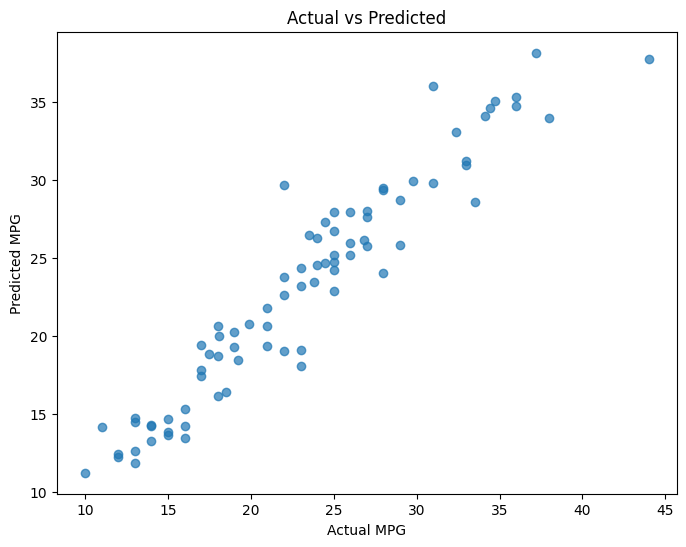

In [64]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.7
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")

plt.title("Actual vs Predicted")

plt.show()

# SHAP Explainability

In [65]:
explainer = shap.TreeExplainer(rf)

shap_values = explainer.shap_values(X_test)

## Summary Plot

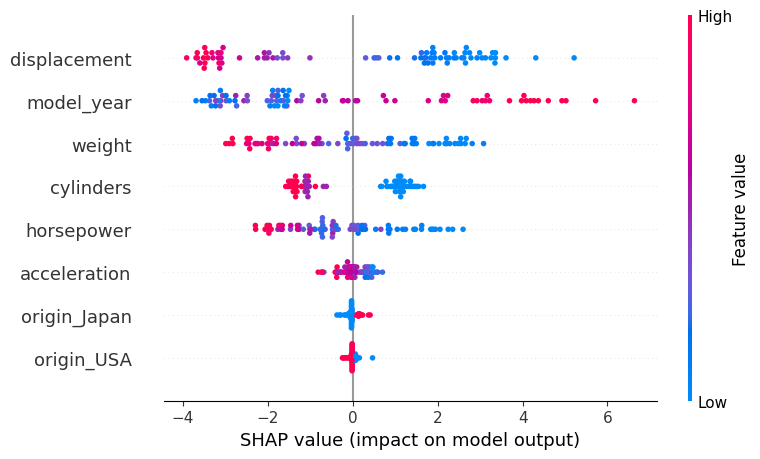

In [66]:
shap.summary_plot(
    shap_values,
    X_test
)

## Bar Plot

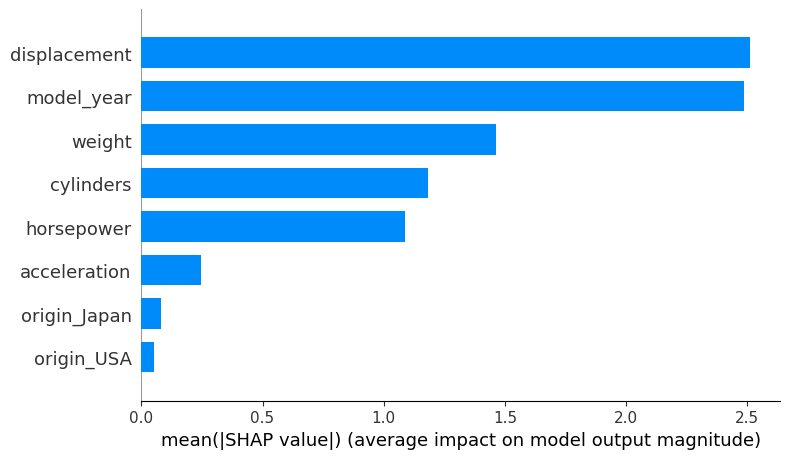

In [67]:
shap.summary_plot(
    shap_values,
    X_test,
    plot_type='bar'
)

# Save Model

In [68]:
import joblib

joblib.dump(
    rf,
    "fuel_efficiency_model.pkl"
)

print("Model Saved Successfully")

Model Saved Successfully


# Prediction Function

In [69]:
def predict_mpg(
        cylinders,
        displacement,
        horsepower,
        weight,
        acceleration,
        model_year,
        origin_Europe,
        origin_Japan):

    data = pd.DataFrame({
        'cylinders':[cylinders],
        'displacement':[displacement],
        'horsepower':[horsepower],
        'weight':[weight],
        'acceleration':[acceleration],
        'model_year':[model_year],
        'origin_Europe':[origin_Europe],
        'origin_Japan':[origin_Japan]
    })

    prediction = rf.predict(data)

    return round(prediction[0],2)

# Example Prediction

predict_mpg(
    cylinders=4,
    displacement=120,
    horsepower=90,
    weight=2200,
    acceleration=16,
    model_year=82,
    origin_Europe=0,
    origin_Japan=1
)